# 🏭 The PrecisionBolt Story: Understanding Units, Spread & the Z-Score

---

## The Setup

You've just joined **PrecisionBolt Inc.** as a Quality Analyst. The company makes high-precision bolts for airplane engines across three factories:

| Factory | Location | Measures bolt diameter in... |
|---|---|---|
| 🇩🇪 **Berlin** | Germany | **Millimeters (mm)** |
| 🇺🇸 **Detroit** | USA | **Inches (in)** |
| 🇯🇵 **Osaka** | Japan | **Centimeters (cm)** |

All three factories produce the **exact same bolt** (target diameter ≈ 12 mm). But because each uses a different measurement unit, the raw numbers look completely different.

Your boss drops a spreadsheet on your desk:

> *"One of these factories is producing inconsistent bolts. The numbers look totally different because of the unit mess. Figure out how to compare them fairly — and find me the factory that needs fixing."*

---

### 🗺️ Roadmap

| Chapter | What You'll Learn |
|---|---|
| **1** | The Unit Trap — why raw numbers are deceiving |
| **2** | Subtracting the mean — helpful, but units remain |
| **3** | Variance vs. Standard Deviation — a tale of units |
| **4** | The Z-Score — the unit killer |
| **5** | Solving the case |


## 📦 Loading the Factory Data

Berlin and Osaka run tight production (std = 0.03 mm). Detroit has a subtle quality issue (std = 0.06 mm — double the spread). But you don't know that yet — you just see raw numbers in different units.


In [30]:
import pandas as pd
import numpy as np


data = pd.read_csv('factory_data.csv')
berlin = data['Berlin'].values
detroit = data['Detroit'].values
osaka = data['Osaka'].values

---

## 🪤 Chapter 1: The Unit Trap

Look at those standard deviations: Berlin's is 0.030, Detroit's is 0.002, Osaka's is 0.003. Berlin looks **15× worse** than Detroit!

But that comparison is nonsensical — we're comparing millimeters to inches to centimeters. It's like saying a 6-foot person is "bigger" than a 190-cm person.

**We can't compare spread across different units.** That's the trap.

---


## ➖ Chapter 2: First Attempt — Subtracting the Mean

A natural first idea: center the data by subtracting the mean. Now positive = above average, negative = below average.


In [18]:
berlin_centered  = berlin  - berlin.mean()
detroit_centered = detroit - detroit.mean()
osaka_centered   = osaka   - osaka.mean()

print("After centering (x − mean):\n")
for name, data, unit in [('Berlin', berlin_centered, 'mm'), ('Detroit', detroit_centered, 'in'), ('Osaka', osaka_centered, 'cm')]:
    print(f"  {name:>8}:  range = [{data.min():.5f}, {data.max():.5f}]  ...still in {unit}!")


After centering (x − mean):

    Berlin:  range = [-0.09744, 0.11538]  ...still in mm!
   Detroit:  range = [-0.00645, 0.00614]  ...still in in!
     Osaka:  range = [-0.00901, 0.00748]  ...still in cm!


**The problem:** When you subtract two values in the same unit, the result is still in that unit.

> 12.045 mm − 12.000 mm = 0.045 **mm** (not unitless!)

Centering moves the middle to zero, but the **units remain**. We still can't compare factories.

---


## 📐 Chapter 3: Variance vs. Standard Deviation — The Units Story

Before we find the solution, let's understand how units flow through our two measures of spread.

**Variance** squares the deviations — so the units get squared too. **Standard deviation** takes the square root to undo that — bringing us back to the original unit. Let's trace it:


In [19]:
bolt = berlin[0]
mean_b = berlin.mean()
dev = bolt - mean_b

print("Tracing units through one Berlin bolt:\n")
print(f"  Raw measurement:       {bolt:.4f}     mm")
print(f"  Deviation (x − mean):  {dev:.4f}     mm        ← still mm")
print(f"  Squared deviation:     {dev**2:.8f}  mm²       ← now mm SQUARED")
print(f"  Variance (avg of all): {berlin.var():.8f}  mm²       ← mm squared")
print(f"  Std Dev (√variance):   {berlin.std():.6f}    mm        ← back to mm")
print()
print("Variance lives in squared units (mm²) — hard to interpret.")
print("Std Dev lives in the original unit (mm) — meaningful, but NOT unitless.")


Tracing units through one Berlin bolt:

  Raw measurement:       12.0149     mm
  Deviation (x − mean):  0.0147     mm        ← still mm
  Squared deviation:     0.00021598  mm²       ← now mm SQUARED
  Variance (avg of all): 0.00086484  mm²       ← mm squared
  Std Dev (√variance):   0.029408    mm        ← back to mm

Variance lives in squared units (mm²) — hard to interpret.
Std Dev lives in the original unit (mm) — meaningful, but NOT unitless.


### The Key Experiment: Do These Change When We Convert Units?

If any of these were unit-free, they'd stay the same when we switch from mm to cm. Let's check:


In [20]:
berlin_in_mm = berlin
berlin_in_cm = berlin / 10.0
berlin_in_in = berlin / 25.4

print("Same Berlin bolts, three unit systems:\n")
print(f"  {'':>14} {'mm':>14} {'cm':>14} {'inches':>14}")
print(f"  {'Mean':>14} {berlin_in_mm.mean():>14.6f} {berlin_in_cm.mean():>14.6f} {berlin_in_in.mean():>14.6f}")
print(f"  {'Std Dev':>14} {berlin_in_mm.std():>14.6f} {berlin_in_cm.std():>14.6f} {berlin_in_in.std():>14.6f}")
print(f"  {'Variance':>14} {berlin_in_mm.var():>14.8f} {berlin_in_cm.var():>14.8f} {berlin_in_in.var():>14.8f}")
print()
print("ALL three metrics change! None is unit-free.")
print()
print("The scaling rules when you multiply data by k:")
print("  • Mean     scales by k    (÷10 → mean becomes 1/10)")
print("  • Std Dev  scales by k    (÷10 → std becomes 1/10)")
print("  • Variance scales by k²   (÷10 → variance becomes 1/100)")


Same Berlin bolts, three unit systems:

                             mm             cm         inches
            Mean      12.000205       1.200021       0.472449
         Std Dev       0.029408       0.002941       0.001158
        Variance     0.00086484     0.00000865     0.00000134

ALL three metrics change! None is unit-free.

The scaling rules when you multiply data by k:
  • Mean     scales by k    (÷10 → mean becomes 1/10)
  • Std Dev  scales by k    (÷10 → std becomes 1/10)
  • Variance scales by k²   (÷10 → variance becomes 1/100)


### Summary So Far

| Quantity | Has Units? | Changes with Unit Conversion? |
|---|---|---|
| Raw data (x) | ✅ Yes | ✅ Yes |
| Centered (x − mean) | ✅ Yes | ✅ Yes |
| Variance | ✅ Yes (squared units!) | ✅ Yes (scales by k²) |
| Standard Deviation | ✅ Yes (original units) | ✅ Yes (scales by k) |

**Everything still has units.** We need something that cancels them out entirely.

---


## ⚡ Chapter 4: The Z-Score — The Unit Killer

Here's the breakthrough. Look at what we have:

- **(x − mean)** is in the original unit (e.g., mm)
- **Std Dev** is also in the original unit (mm)

What if we **divide** one by the other?

$$z = \frac{x - \text{mean}}{\text{std dev}} = \frac{\text{mm}}{\text{mm}} = \text{unitless!}$$

The units cancel. This ratio is the **Z-Score** — and it tells you one thing:

> **"How many standard deviations away from the mean is this data point?"**


In [21]:
bolt = berlin[0]
z = (bolt - berlin.mean()) / berlin.std()

print(f"Berlin bolt:  {bolt:.4f} mm")
print(f"Z-score:      ({bolt:.4f} - {berlin.mean():.4f}) / {berlin.std():.4f}  =  {z:.4f}")
print(f"\nThis bolt is {abs(z):.2f} standard deviations {'above' if z > 0 else 'below'} the mean.")


Berlin bolt:  12.0149 mm
Z-score:      (12.0149 - 12.0002) / 0.0294  =  0.4997

This bolt is 0.50 standard deviations above the mean.


### The Proof: Z-Scores Don't Change with Units

The same physical bolt, z-scored in three different unit systems:


In [22]:
bolt_mm = berlin[0]
bolt_cm = bolt_mm / 10.0
bolt_in = bolt_mm / 25.4

z_mm = (bolt_mm - berlin_in_mm.mean()) / berlin_in_mm.std()
z_cm = (bolt_cm - berlin_in_cm.mean()) / berlin_in_cm.std()
z_in = (bolt_in - berlin_in_in.mean()) / berlin_in_in.std()

print("One bolt, three unit systems:\n")
print(f"  In mm:     z = ({bolt_mm:.4f} - {berlin_in_mm.mean():.4f}) / {berlin_in_mm.std():.4f}  =  {z_mm:.6f}")
print(f"  In cm:     z = ({bolt_cm:.5f} - {berlin_in_cm.mean():.5f}) / {berlin_in_cm.std():.5f}  =  {z_cm:.6f}")
print(f"  In inches: z = ({bolt_in:.6f} - {berlin_in_in.mean():.6f}) / {berlin_in_in.std():.6f}  =  {z_in:.6f}")
print(f"\n✅ All identical! The conversion factor appears in BOTH numerator and denominator, so it cancels.")


One bolt, three unit systems:

  In mm:     z = (12.0149 - 12.0002) / 0.0294  =  0.499735
  In cm:     z = (1.20149 - 1.20002) / 0.00294  =  0.499735
  In inches: z = (0.473028 - 0.472449) / 0.001158  =  0.499735

✅ All identical! The conversion factor appears in BOTH numerator and denominator, so it cancels.


### Reading Z-Scores

| Z-Score | Meaning |
|---|---|
| **0** | Exactly average |
| **±1** | Somewhat above/below average (~68% of data is within here) |
| **±2** | Quite unusual (~5% of data is beyond this) |
| **±3** | Extremely rare (~0.3% of data is beyond this) |

Now let's z-score all three factories and put them on one plot for the first time:


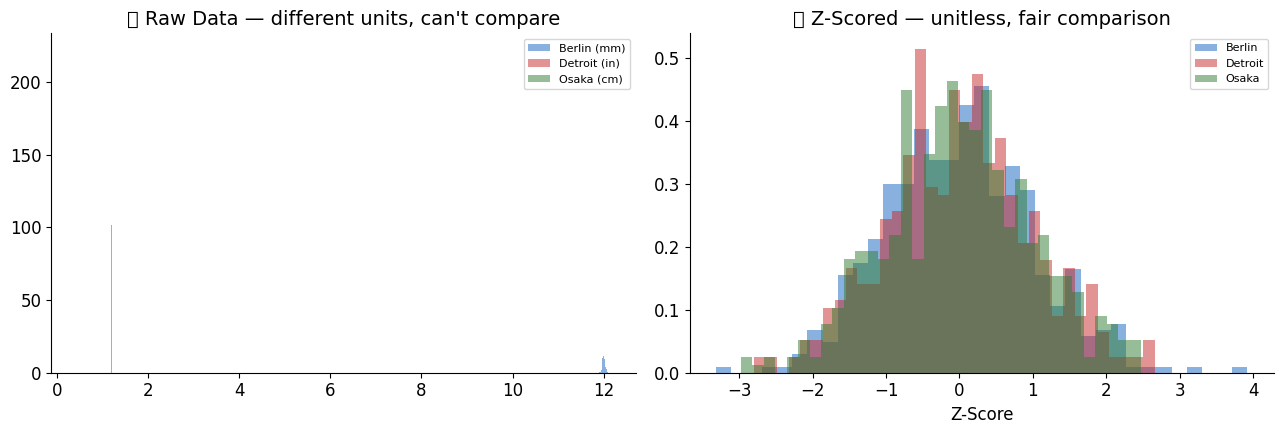

Now we can SEE it: Detroit (red) is wider — more variable.
Berlin and Osaka overlap almost perfectly — same quality.


In [23]:
berlin_z  = (berlin  - berlin.mean())  / berlin.std()
detroit_z = (detroit - detroit.mean()) / detroit.std()
osaka_z   = (osaka   - osaka.mean())   / osaka.std()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Before: raw data — can't compare
for data, label, c in [(berlin, 'Berlin (mm)', '#1565C0'), (detroit, 'Detroit (in)', '#C62828'), (osaka, 'Osaka (cm)', '#2E7D32')]:
    axes[0].hist(data, bins=35, alpha=0.5, color=c, label=label, density=True)
axes[0].set_title('❌ Raw Data — different units, can\'t compare')
axes[0].legend(fontsize=8)

# After: z-scored — now comparable
for data, label, c in [(berlin_z, 'Berlin', '#1565C0'), (detroit_z, 'Detroit', '#C62828'), (osaka_z, 'Osaka', '#2E7D32')]:
    axes[1].hist(data, bins=35, alpha=0.5, color=c, label=label, density=True)
axes[1].set_title('✅ Z-Scored — unitless, fair comparison')
axes[1].set_xlabel('Z-Score')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Now we can SEE it: Detroit (red) is wider — more variable.")
print("Berlin and Osaka overlap almost perfectly — same quality.")


---

## 🔍 Chapter 5: Solving the Case

With z-scores on a common scale, let's convert everything to mm and compute global z-scores to make the final comparison:


In [24]:
# Convert all to mm
all_mm = np.concatenate([berlin_mm, detroit_mm, osaka_mm])
global_mean, global_std = all_mm.mean(), all_mm.std()

berlin_gz  = (berlin_mm  - global_mean) / global_std
detroit_gz = (detroit_mm - global_mean) / global_std
osaka_gz   = (osaka_mm   - global_mean) / global_std

print("Global Z-Score Analysis\n")
print(f"  {'Factory':<10} {'Std Dev (mm)':>14} {'% bolts |z|>2':>16}")
print(f"  {'-'*44}")
for name, mm_data, gz in [('Berlin', berlin_mm, berlin_gz), ('Detroit', detroit_mm, detroit_gz), ('Osaka', osaka_mm, osaka_gz)]:
    pct = (np.abs(gz) > 2).mean() * 100
    flag = ' 🚨' if pct > 8 else ' ✅'
    print(f"  {name:<10} {mm_data.std():>14.4f} {pct:>15.1f}%{flag}")

print(f"\n📋 FINDING: Detroit has ~2x the variability of Berlin and Osaka.")
print(f"   This was invisible in raw data because of the unit differences.")
print(f"   The Z-Score made it visible.")


Global Z-Score Analysis

  Factory      Std Dev (mm)    % bolts |z|>2
  --------------------------------------------
  Berlin             0.0294             0.6% ✅
  Detroit            0.0586            16.8% 🚨
  Osaka              0.0303             0.4% ✅

📋 FINDING: Detroit has ~2x the variability of Berlin and Osaka.
   This was invisible in raw data because of the unit differences.
   The Z-Score made it visible.


---

## 🧠 Cheat Sheet

### The Journey

| Step | What It Does | Removes Units? |
|---|---|---|
| **Raw data (x)** | Nothing | ❌ No |
| **Centered (x − mean)** | Shifts middle to zero | ❌ No — still has original units |
| **Z-Score: (x − mean) / std** | Centers AND scales | ✅ **Yes — unitless!** |

### Z-Score in One Sentence

> The z-score tells you **how many standard deviations a value is from the mean** — and because both numerator and denominator share the same unit, the units cancel, making it a universal, unit-free measure.

### Why This Matters in ML

Many algorithms are sensitive to feature scale. If one feature ranges 0–1,000 and another 0–1, the algorithm may think the first is more "important" just because the numbers are bigger. **Z-score normalization** (standardization) puts every feature on the same unitless scale — that's exactly what `StandardScaler` in scikit-learn does.
